# Notebook 1 · DCGAN para generar rostros humanos

**CADI Deep Learning Conceptos** · Docente: Nidia Stella García Roa
**Estudiante:** Ruby Dayana Cárdenas Gómez · Universidad de Cundinamarca · Noviembre 2026

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RubyDayana/modelos-generativos-gan-difusion/blob/main/notebooks/01-DCGAN-Rostros.ipynb)

En este notebook implemento desde cero una **Red Generativa Adversaria Convolucional Profunda (DCGAN)** en PyTorch, siguiendo la idea del artículo *Implementing a Generative Adversarial Network (GAN/DCGAN) to Draw Human Faces*: dos redes que compiten, un **generador** que dibuja rostros a partir de ruido y un **discriminador** que intenta distinguir los rostros reales de los falsos.

Contenido:

1. Conceptos clave (generador, discriminador, entrenamiento adversarial, espacio latente)
2. Preparación del entorno
3. Preparación de los datos (≈13 400 rostros reales)
4. Arquitectura del generador y del discriminador
5. Entrenamiento adversarial
6. Resultados del entrenamiento
7. Comparación con una GAN básica de capas densas
8. Exploración del espacio latente
9. Pruebas: ¿la red memoriza o genera rostros nuevos?
10. Análisis y conclusiones

## 1. Conceptos clave

Una **GAN** (Goodfellow et al., 2014) está formada por dos redes neuronales que se entrenan al mismo tiempo con objetivos opuestos:

| Componente | Entrada | Salida | Objetivo |
|---|---|---|---|
| **Generador** $G$ | vector de ruido $z \sim \mathcal{N}(0, I)$ de 100 dimensiones | imagen $64\times64$ | engañar al discriminador |
| **Discriminador** $D$ | imagen $64\times64$ | probabilidad de que la imagen sea real | no dejarse engañar |

El entrenamiento es un **juego minimax** entre las dos redes:

$$\min_G \max_D \; \mathbb{E}_{x\sim p_{datos}}[\log D(x)] + \mathbb{E}_{z\sim p_z}[\log(1-D(G(z)))]$$

En la práctica se alternan dos pasos en cada lote: primero se actualiza $D$ con imágenes reales (etiqueta 1) y falsas (etiqueta 0); luego se actualiza $G$ para que $D$ clasifique sus imágenes como reales. El equilibrio teórico se alcanza cuando $D(x)=0{,}5$ para todo $x$, es decir, cuando el discriminador ya no puede distinguir.

El vector $z$ vive en el **espacio latente**: un espacio de 100 dimensiones donde cada punto corresponde a un rostro. El generador aprende a convertir ese espacio en la distribución de rostros reales, por lo que moverse suavemente en $z$ debería producir cambios suaves en la cara.

La **DCGAN** (Radford et al., 2016) es la versión convolucional, con unas reglas de diseño que hacen el entrenamiento estable:

- Reemplazar *pooling* por convoluciones con paso 2 (discriminador) y convoluciones transpuestas (generador).
- Usar *Batch Normalization* en ambas redes (excepto en la salida de $G$ y la entrada de $D$).
- ReLU en el generador y Tanh en su salida; LeakyReLU (0,2) en el discriminador.
- Pesos iniciales $\mathcal{N}(0; 0{,}02)$ y optimizador Adam con $lr=0{,}0002$ y $\beta_1=0{,}5$.

## 2. Preparación del entorno

In [1]:
import os, time, random, subprocess
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

SEMILLA = 42
random.seed(SEMILLA); np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)

dispositivo = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if dispositivo.type == 'cpu':
    torch.set_num_threads(max(1, os.cpu_count()))
os.makedirs('figuras', exist_ok=True)

print('PyTorch:', torch.__version__)
print('Dispositivo:', dispositivo, '| hilos CPU:', torch.get_num_threads())

PyTorch: 2.15.0+cu132
Dispositivo: cpu | hilos CPU: 2


## 3. Preparación de los datos

El artículo de referencia usa CelebA, que pesa más de 1 GB y en Colab suele fallar por el límite de descargas de Google Drive. Para que el notebook se pueda reproducir sin cuentas ni descargas manuales, usé el repositorio público **facial_expressions** (licencia Apache 2.0), que contiene unas 13 700 fotografías de rostros ya recortados (la mayoría de 350×350 px en escala de grises).

Pasos de preparación:

1. Clonar el repositorio (si no está ya en la carpeta).
2. Descartar imágenes con lado menor a 64 px (quedarían muy borrosas al ampliarlas).
3. Convertir a escala de grises, recortar el cuadrado central y redimensionar a **64×64**.
4. Separar un 5 % de imágenes como **conjunto de control** que la GAN nunca ve (lo uso en la sección 9 para comprobar si la red memoriza).
5. Normalizar los píxeles a $[-1, 1]$, el mismo rango de la salida Tanh del generador.

> Nota: por tratarse de fotografías de personas reales, en este trabajo no muestro las imágenes de entrenamiento una por una; solo muestro estadísticas y el *rostro promedio* del conjunto.

In [2]:
CARPETA = 'facial_expressions/images'
if not os.path.isdir(CARPETA):
    subprocess.run(['git', 'clone', '--depth', '1',
                    'https://github.com/muxspace/facial_expressions.git'], check=True)

CACHE = 'rostros64.npy'
TAM = 64
if os.path.exists(CACHE):
    datos = np.load(CACHE)
else:
    archivos = sorted(f for f in os.listdir(CARPETA) if f.lower().endswith(('.jpg', '.jpeg', '.png')))
    lista, descartadas = [], 0
    for f in archivos:
        try:
            im = Image.open(os.path.join(CARPETA, f)).convert('L')
        except Exception:
            descartadas += 1; continue
        w, h = im.size
        if min(w, h) < TAM:
            descartadas += 1; continue
        m = min(w, h)
        im = im.crop(((w - m) // 2, (h - m) // 2, (w + m) // 2, (h + m) // 2)).resize((TAM, TAM), Image.BICUBIC)
        lista.append(np.asarray(im, dtype=np.uint8))
    datos = np.stack(lista)
    np.save(CACHE, datos)
    print('Imágenes descartadas:', descartadas)

idx = np.random.RandomState(SEMILLA).permutation(len(datos))
n_control = int(0.05 * len(datos))
control_np, entren_np = datos[idx[:n_control]], datos[idx[n_control:]]
print('Total de rostros 64×64:', len(datos))
print('Entrenamiento:', len(entren_np), '| Control (no se usa para entrenar):', len(control_np))
print('Media de intensidad: %.1f | desviación: %.1f' % (entren_np.mean(), entren_np.std()))

Imágenes descartadas: 310
Total de rostros 64×64: 13408
Entrenamiento: 12738 | Control (no se usa para entrenar): 670


Media de intensidad: 120.0 | desviación: 52.9


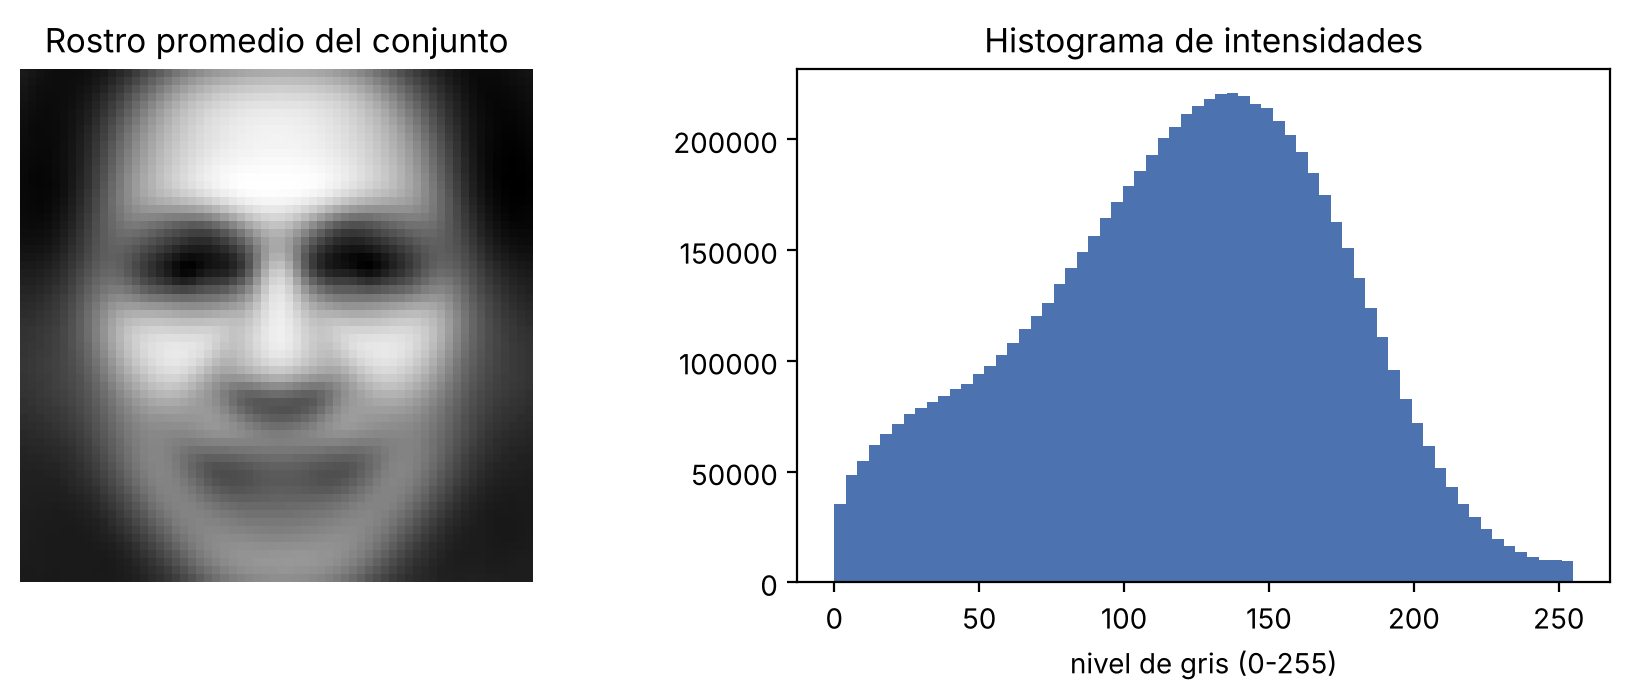

Tensor de entrenamiento: (12738, 1, 64, 64) | rango [-1.0, 1.0]


In [3]:
def a_tensor(arr):
    return torch.from_numpy(arr).float().div(127.5).sub(1).unsqueeze(1)   # [N,1,64,64] en [-1,1]

X_entren = a_tensor(entren_np)
X_control = a_tensor(control_np)

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ax[0].imshow(entren_np.mean(0), cmap='gray'); ax[0].set_title('Rostro promedio del conjunto'); ax[0].axis('off')
ax[1].hist(entren_np.ravel()[::7], bins=64, color='#4C72B0')
ax[1].set_title('Histograma de intensidades'); ax[1].set_xlabel('nivel de gris (0-255)')
plt.tight_layout(); plt.savefig('figuras/01-datos-promedio-histograma.png', dpi=150); plt.show()
print('Tensor de entrenamiento:', tuple(X_entren.shape), '| rango [%.1f, %.1f]' % (X_entren.min(), X_entren.max()))

El rostro promedio muestra que las fotos están bien alineadas: ojos, nariz y boca caen casi siempre en la misma posición. Esto facilita el trabajo del generador, porque solo tiene que aprender la variación alrededor de esa estructura común.

## 4. Arquitectura

### 4.1 Generador
Recibe $z$ de forma $100\times1\times1$ y lo amplía con convoluciones transpuestas: $1 \to 4 \to 8 \to 16 \to 32 \to 64$ píxeles, mientras reduce los canales. Por las limitaciones de cómputo usé `ngf = 48` mapas base (el artículo original de DCGAN usa 64).

### 4.2 Discriminador
Es el espejo del generador: convoluciones con paso 2 reducen $64 \to 32 \to 16 \to 8 \to 4 \to 1$. La última capa no tiene sigmoide porque uso `BCEWithLogitsLoss`, que combina sigmoide y entropía cruzada de forma numéricamente estable.

In [4]:
NZ, NGF, NDF = 100, 48, 48

class Generador(nn.Module):
    def __init__(self, nz=NZ, ngf=NGF):
        super().__init__()
        self.red = nn.Sequential(
            nn.ConvTranspose2d(nz, ngf * 8, 4, 1, 0, bias=False), nn.BatchNorm2d(ngf * 8), nn.ReLU(True),       # 4x4
            nn.ConvTranspose2d(ngf * 8, ngf * 4, 4, 2, 1, bias=False), nn.BatchNorm2d(ngf * 4), nn.ReLU(True),  # 8x8
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=False), nn.BatchNorm2d(ngf * 2), nn.ReLU(True),  # 16x16
            nn.ConvTranspose2d(ngf * 2, ngf, 4, 2, 1, bias=False), nn.BatchNorm2d(ngf), nn.ReLU(True),          # 32x32
            nn.ConvTranspose2d(ngf, 1, 4, 2, 1, bias=False), nn.Tanh())                                         # 64x64
    def forward(self, z):
        return self.red(z)

class Discriminador(nn.Module):
    def __init__(self, ndf=NDF):
        super().__init__()
        self.red = nn.Sequential(
            nn.Conv2d(1, ndf, 4, 2, 1, bias=False), nn.LeakyReLU(0.2, True),                                  # 32x32
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False), nn.BatchNorm2d(ndf * 2), nn.LeakyReLU(0.2, True),     # 16x16
            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1, bias=False), nn.BatchNorm2d(ndf * 4), nn.LeakyReLU(0.2, True), # 8x8
            nn.Conv2d(ndf * 4, ndf * 8, 4, 2, 1, bias=False), nn.BatchNorm2d(ndf * 8), nn.LeakyReLU(0.2, True), # 4x4
            nn.Conv2d(ndf * 8, 1, 4, 1, 0, bias=False))                                                        # 1x1 (logit)
    def forward(self, x):
        return self.red(x).view(-1)

def iniciar_pesos(m):
    # Regla de la DCGAN: pesos N(0, 0.02) y BatchNorm con gamma N(1, 0.02)
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

G = Generador().to(dispositivo); G.apply(iniciar_pesos)
D = Discriminador().to(dispositivo); D.apply(iniciar_pesos)
contar = lambda m: sum(p.numel() for p in m.parameters())
print('Parámetros del generador:     {:,}'.format(contar(G)).replace(',', ' '))
print('Parámetros del discriminador: {:,}'.format(contar(D)).replace(',', ' '))

# Recorrido de formas a través del generador
x = torch.randn(1, NZ, 1, 1, device=dispositivo)
print('\nForma de la entrada z:', tuple(x.shape))
for capa in G.red:
    x = capa(x) if not isinstance(capa, nn.BatchNorm2d) else x
    if isinstance(capa, nn.ConvTranspose2d):
        print(f'{capa.__class__.__name__:16s} -> {tuple(x.shape)}')

Parámetros del generador:     2 164 896
Parámetros del discriminador: 1 556 544

Forma de la entrada z: (1, 100, 1, 1)
ConvTranspose2d  -> (1, 384, 4, 4)
ConvTranspose2d  -> (1, 192, 8, 8)
ConvTranspose2d  -> (1, 96, 16, 16)
ConvTranspose2d  -> (1, 48, 32, 32)
ConvTranspose2d  -> (1, 1, 64, 64)


## 5. Entrenamiento adversarial

Hiperparámetros (siguiendo a Radford et al., 2016, con ajustes por el hardware):

| Parámetro | Valor |
|---|---|
| Tamaño de lote | 64 |
| Épocas | 25 |
| Optimizador | Adam, $lr = 0{,}0002$, $\beta_1 = 0{,}5$, $\beta_2 = 0{,}999$ |
| Pérdida | Entropía cruzada binaria (`BCEWithLogitsLoss`) |
| Suavizado de etiquetas | etiqueta real = 0,9 (*one-sided label smoothing*, Salimans et al., 2016) |
| Aumento de datos | volteo horizontal aleatorio |

Cada iteración tiene dos pasos:

1. **Paso del discriminador:** maximiza $\log D(x) + \log(1 - D(G(z)))$. Se usa `detach()` sobre las imágenes falsas para no propagar gradiente al generador.
2. **Paso del generador:** en lugar de minimizar $\log(1 - D(G(z)))$, maximiza $\log D(G(z))$ (versión *no saturante* propuesta por Goodfellow et al.), porque al inicio $D$ rechaza fácilmente las imágenes falsas y la versión original casi no da gradiente.

Guardo un lote de **ruido fijo** (64 vectores $z$) para ver cómo evolucionan los mismos rostros a lo largo de las épocas.

In [5]:
EPOCAS, LOTE, LR = 25, 64, 2e-4
ETIQ_REAL, ETIQ_FALSA = 0.9, 0.0

cargador = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X_entren), batch_size=LOTE,
                                       shuffle=True, drop_last=True,
                                       generator=torch.Generator().manual_seed(SEMILLA))
criterio = nn.BCEWithLogitsLoss()
opt_D = torch.optim.Adam(D.parameters(), lr=LR, betas=(0.5, 0.999))
opt_G = torch.optim.Adam(G.parameters(), lr=LR, betas=(0.5, 0.999))
ruido_fijo = torch.randn(64, NZ, 1, 1, device=dispositivo)

hist = {'loss_D': [], 'loss_G': [], 'D_x': [], 'D_Gz': []}
por_epoca = []          # resumen por época
instantaneas = {}       # imágenes del ruido fijo en algunas épocas
t0 = time.time()
for epoca in range(1, EPOCAS + 1):
    G.train(); D.train(); te = time.time()
    for (reales,) in cargador:
        reales = reales.to(dispositivo)
        voltear = torch.rand(reales.size(0), 1, 1, 1, device=dispositivo) < 0.5
        reales = torch.where(voltear, reales.flip(3), reales)
        b = reales.size(0)

        # (1) Discriminador
        z = torch.randn(b, NZ, 1, 1, device=dispositivo)
        falsas = G(z)
        opt_D.zero_grad()
        out_real = D(reales)
        out_falsa = D(falsas.detach())
        loss_D = criterio(out_real, torch.full((b,), ETIQ_REAL, device=dispositivo)) + \
                 criterio(out_falsa, torch.full((b,), ETIQ_FALSA, device=dispositivo))
        loss_D.backward(); opt_D.step()

        # (2) Generador (pérdida no saturante: quiere que D diga "real")
        opt_G.zero_grad()
        out_g = D(falsas)
        loss_G = criterio(out_g, torch.ones(b, device=dispositivo))
        loss_G.backward(); opt_G.step()

        hist['loss_D'].append(loss_D.item()); hist['loss_G'].append(loss_G.item())
        hist['D_x'].append(torch.sigmoid(out_real).mean().item())
        hist['D_Gz'].append(torch.sigmoid(out_falsa).mean().item())

    n = len(cargador)
    res = {k: float(np.mean(v[-n:])) for k, v in hist.items()}
    res['epoca'] = epoca; res['seg'] = time.time() - te
    por_epoca.append(res)
    if epoca in (1, 2, 3, 5, 10, 15, 20, 25):
        G.eval()
        with torch.no_grad():
            instantaneas[epoca] = G(ruido_fijo).cpu()
    print(f"Época {epoca:2d}/{EPOCAS} | loss_D {res['loss_D']:.3f} | loss_G {res['loss_G']:.3f} | "
          f"D(x) {res['D_x']:.3f} | D(G(z)) {res['D_Gz']:.3f} | {res['seg']:.0f} s")

t_total = time.time() - t0
print(f'\nIteraciones totales: {len(hist["loss_D"])} | tiempo total: {t_total/60:.1f} min en {dispositivo}')
torch.save({'G': G.state_dict(), 'D': D.state_dict()}, 'dcgan-rostros.pt')

Época  1/25 | loss_D 0.620 | loss_G 6.199 | D(x) 0.817 | D(G(z)) 0.087 | 110 s


Época  2/25 | loss_D 0.656 | loss_G 5.118 | D(x) 0.796 | D(G(z)) 0.104 | 171 s


Época  3/25 | loss_D 0.682 | loss_G 4.648 | D(x) 0.773 | D(G(z)) 0.125 | 242 s


Época  4/25 | loss_D 0.662 | loss_G 4.373 | D(x) 0.772 | D(G(z)) 0.124 | 110 s


Época  5/25 | loss_D 0.668 | loss_G 3.949 | D(x) 0.768 | D(G(z)) 0.128 | 107 s


Época  6/25 | loss_D 0.688 | loss_G 3.790 | D(x) 0.755 | D(G(z)) 0.144 | 108 s


... (15 outputs left out)

Época 22/25 | loss_D 0.824 | loss_G 2.638 | D(x) 0.687 | D(G(z)) 0.211 | 117 s


Época 23/25 | loss_D 0.804 | loss_G 2.647 | D(x) 0.693 | D(G(z)) 0.208 | 115 s


Época 24/25 | loss_D 0.829 | loss_G 2.653 | D(x) 0.685 | D(G(z)) 0.212 | 115 s


Época 25/25 | loss_D 0.815 | loss_G 2.657 | D(x) 0.689 | D(G(z)) 0.210 | 111 s

Iteraciones totales: 4975 | tiempo total: 50.2 min en cpu


## 6. Resultados del entrenamiento

### 6.1 Curvas de pérdida y salidas del discriminador

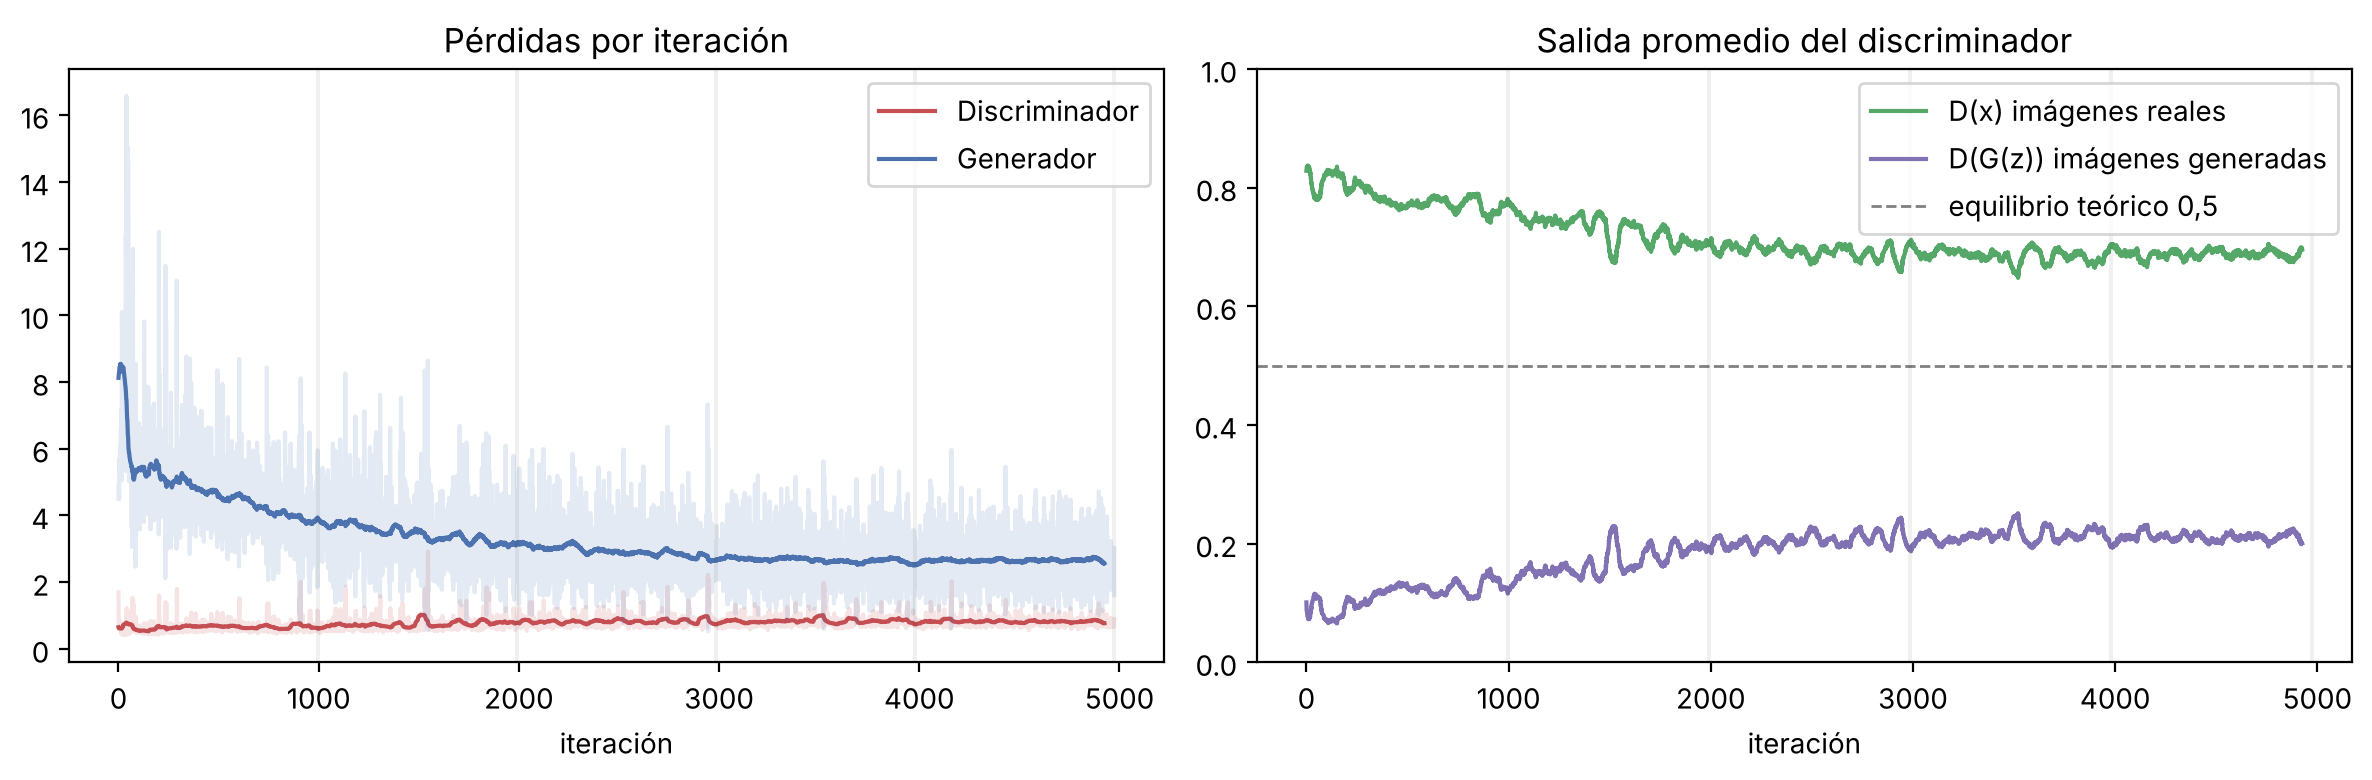

Época | loss_D | loss_G | D(x)  | D(G(z)) | seg
    1 | 0.620  | 6.199  | 0.817 | 0.087   | 110
    2 | 0.656  | 5.118  | 0.796 | 0.104   | 171
    3 | 0.682  | 4.648  | 0.773 | 0.125   | 242
    5 | 0.668  | 3.949  | 0.768 | 0.128   | 107
   10 | 0.795  | 3.207  | 0.709 | 0.190   | 112
   15 | 0.851  | 2.785  | 0.685 | 0.214   | 114
   20 | 0.854  | 2.657  | 0.680 | 0.219   | 116
   25 | 0.815  | 2.657  | 0.689 | 0.210   | 111


In [6]:
def suavizar(v, k=50):
    v = np.asarray(v); return np.convolve(v, np.ones(k) / k, mode='valid')

it_ep = len(cargador)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist['loss_D'], alpha=.15, color='#C44E52'); ax[0].plot(suavizar(hist['loss_D']), color='#C44E52', label='Discriminador')
ax[0].plot(hist['loss_G'], alpha=.15, color='#4C72B0'); ax[0].plot(suavizar(hist['loss_G']), color='#4C72B0', label='Generador')
ax[0].set_title('Pérdidas por iteración'); ax[0].set_xlabel('iteración'); ax[0].legend()
ax[1].plot(suavizar(hist['D_x']), label='D(x) imágenes reales', color='#55A868')
ax[1].plot(suavizar(hist['D_Gz']), label='D(G(z)) imágenes generadas', color='#8172B3')
ax[1].axhline(0.5, ls='--', color='gray', lw=1, label='equilibrio teórico 0,5')
ax[1].set_ylim(0, 1); ax[1].set_title('Salida promedio del discriminador'); ax[1].set_xlabel('iteración'); ax[1].legend()
for a in ax:
    for e in range(5, EPOCAS + 1, 5): a.axvline(e * it_ep, color='k', alpha=.06)
plt.tight_layout(); plt.savefig('figuras/02-curvas-entrenamiento.png', dpi=150); plt.show()

print('Época | loss_D | loss_G | D(x)  | D(G(z)) | seg')
for r in por_epoca:
    if r['epoca'] in (1, 2, 3, 5, 10, 15, 20, 25):
        print(f"{r['epoca']:5d} | {r['loss_D']:.3f}  | {r['loss_G']:.3f}  | {r['D_x']:.3f} | {r['D_Gz']:.3f}   | {r['seg']:.0f}")

### 6.2 Evolución de los mismos 16 vectores de ruido a lo largo de las épocas

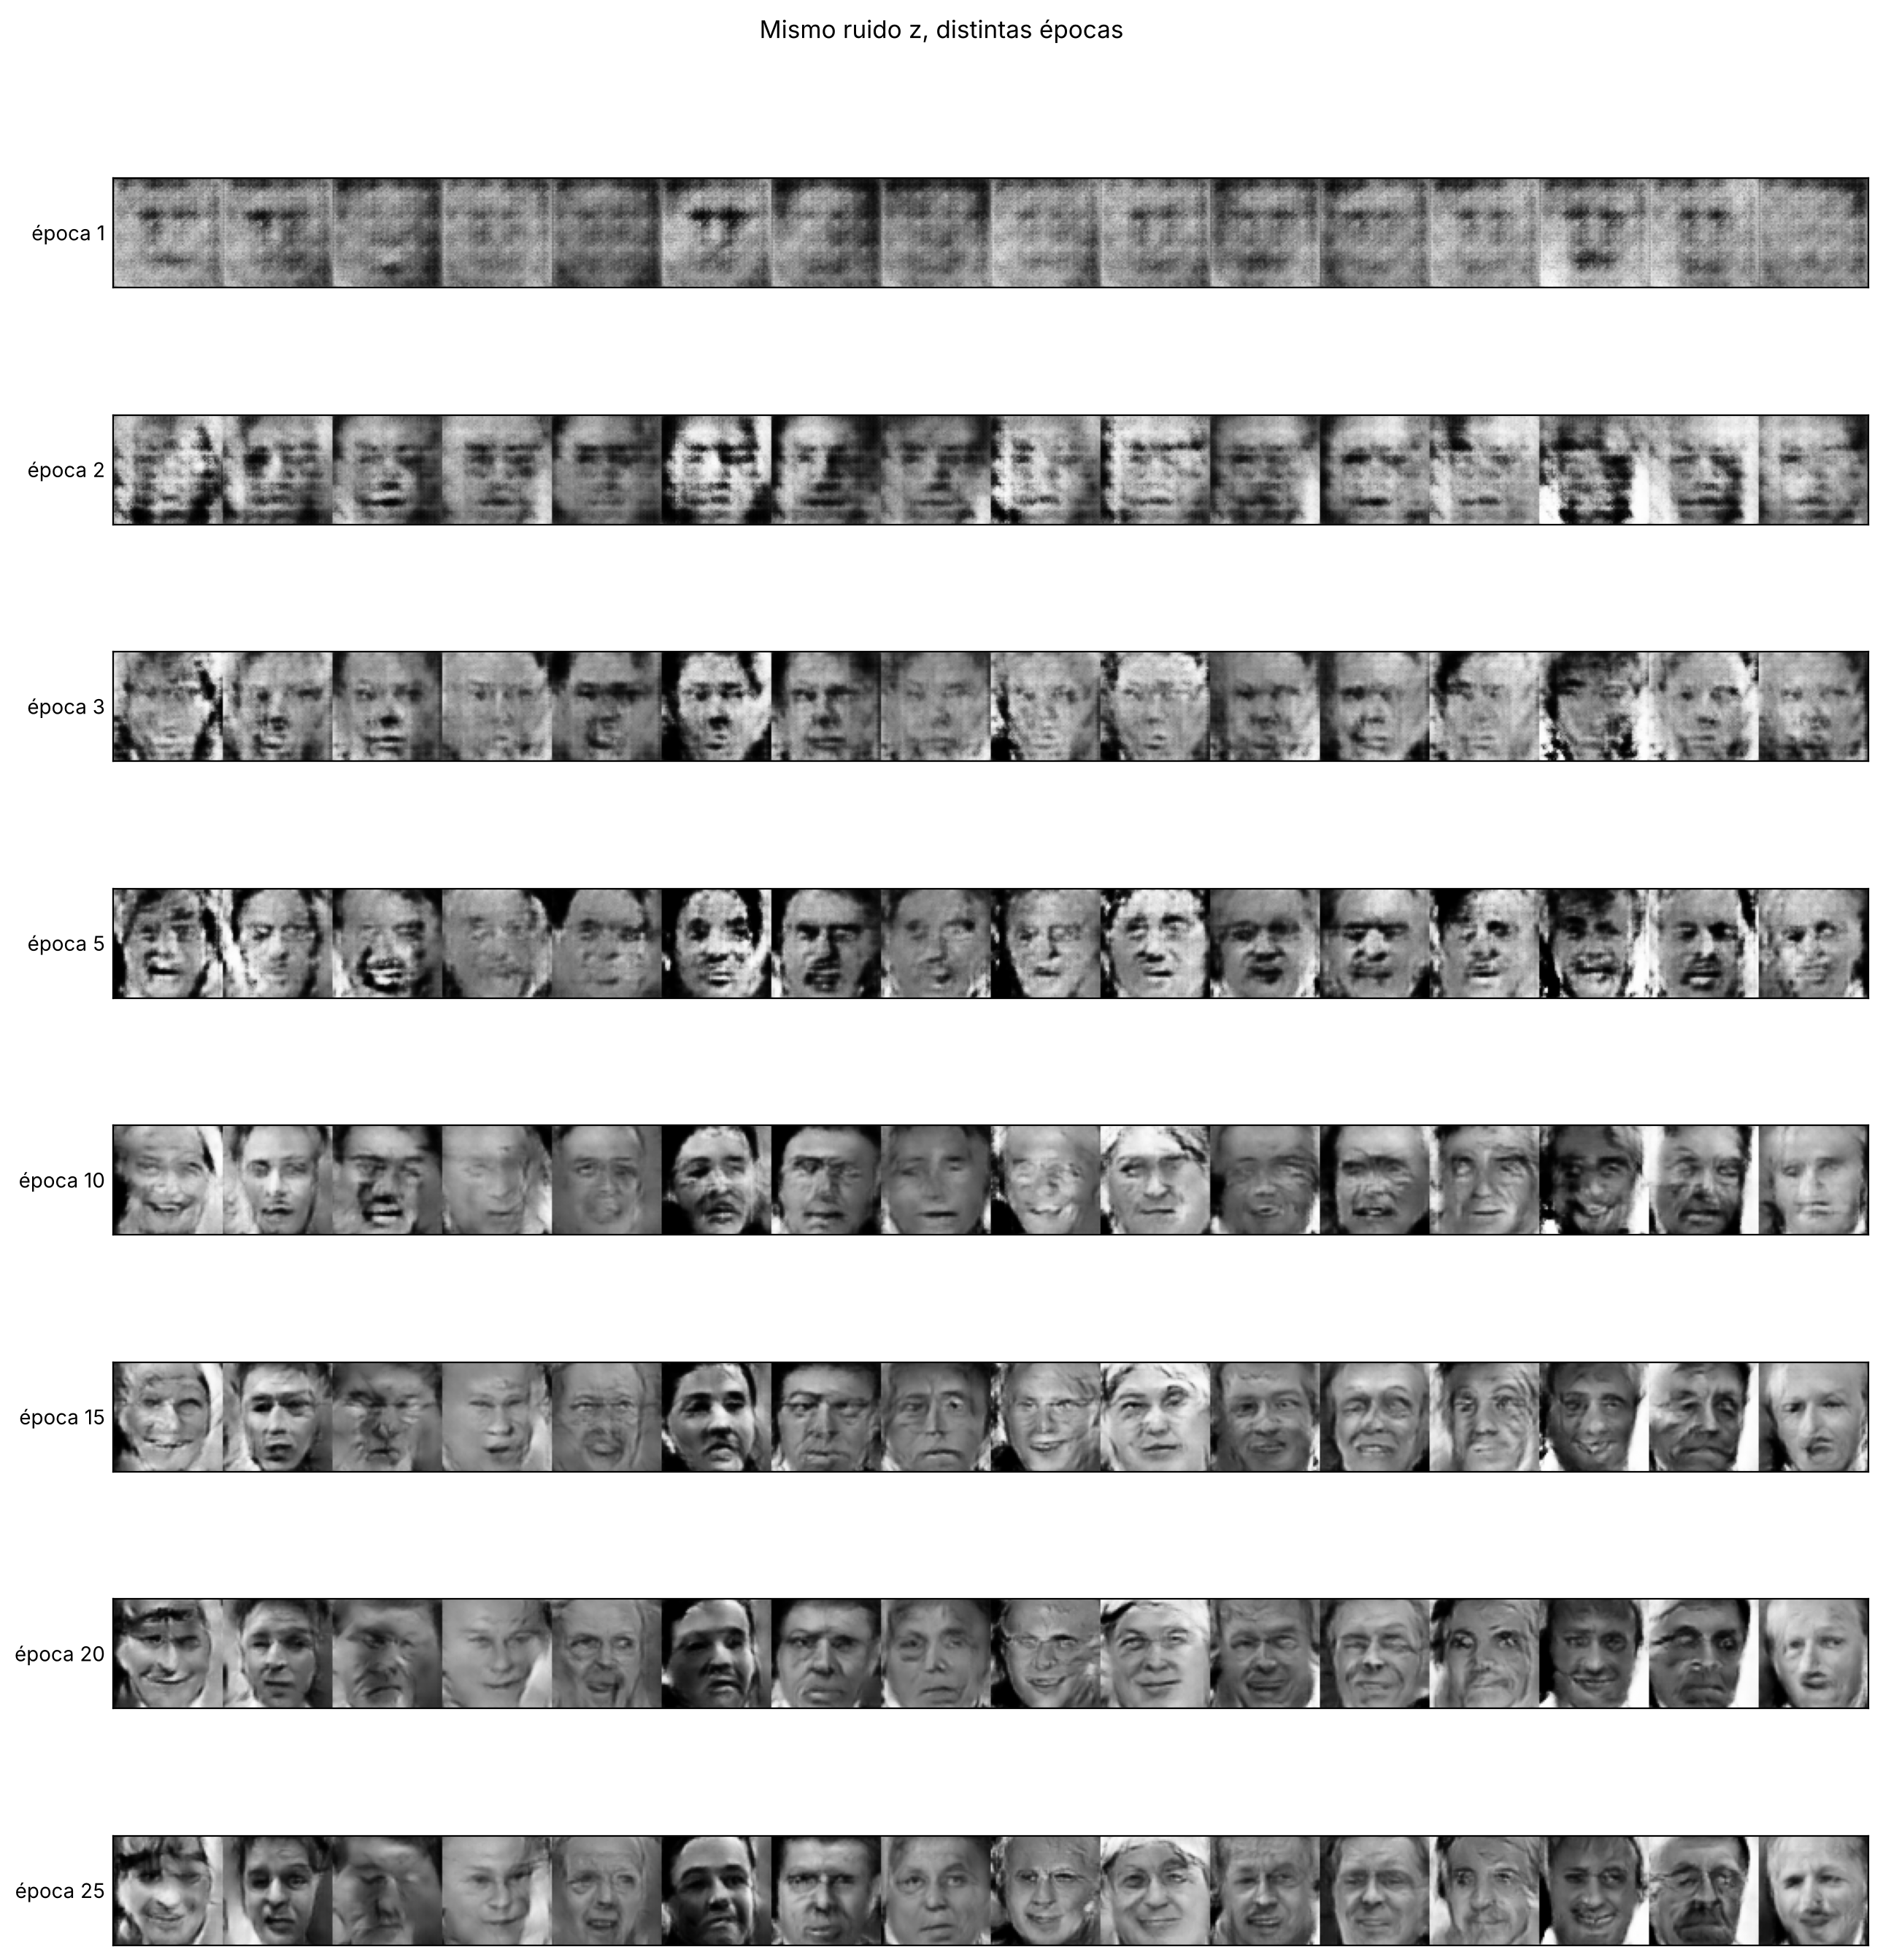

In [7]:
def a_img(t):
    return (t.squeeze(1).clamp(-1, 1).add(1).mul(127.5)).numpy().astype(np.uint8)

ep_mostrar = sorted(instantaneas)
fig, ax = plt.subplots(len(ep_mostrar), 1, figsize=(13, 1.75 * len(ep_mostrar)))
for i, e in enumerate(ep_mostrar):
    fila = np.concatenate(list(a_img(instantaneas[e][:16])), axis=1)
    ax[i].imshow(fila, cmap='gray', vmin=0, vmax=255); ax[i].set_xticks([]); ax[i].set_yticks([])
    ax[i].set_ylabel(f'época {e}', rotation=0, ha='right', va='center', fontsize=10)
plt.suptitle('Mismo ruido z, distintas épocas', y=1.0)
plt.tight_layout(); plt.savefig('figuras/03-evolucion-epocas.png', dpi=150, bbox_inches='tight'); plt.show()

### 6.3 Rostros generados al final del entrenamiento (64 muestras de ruido fijo)

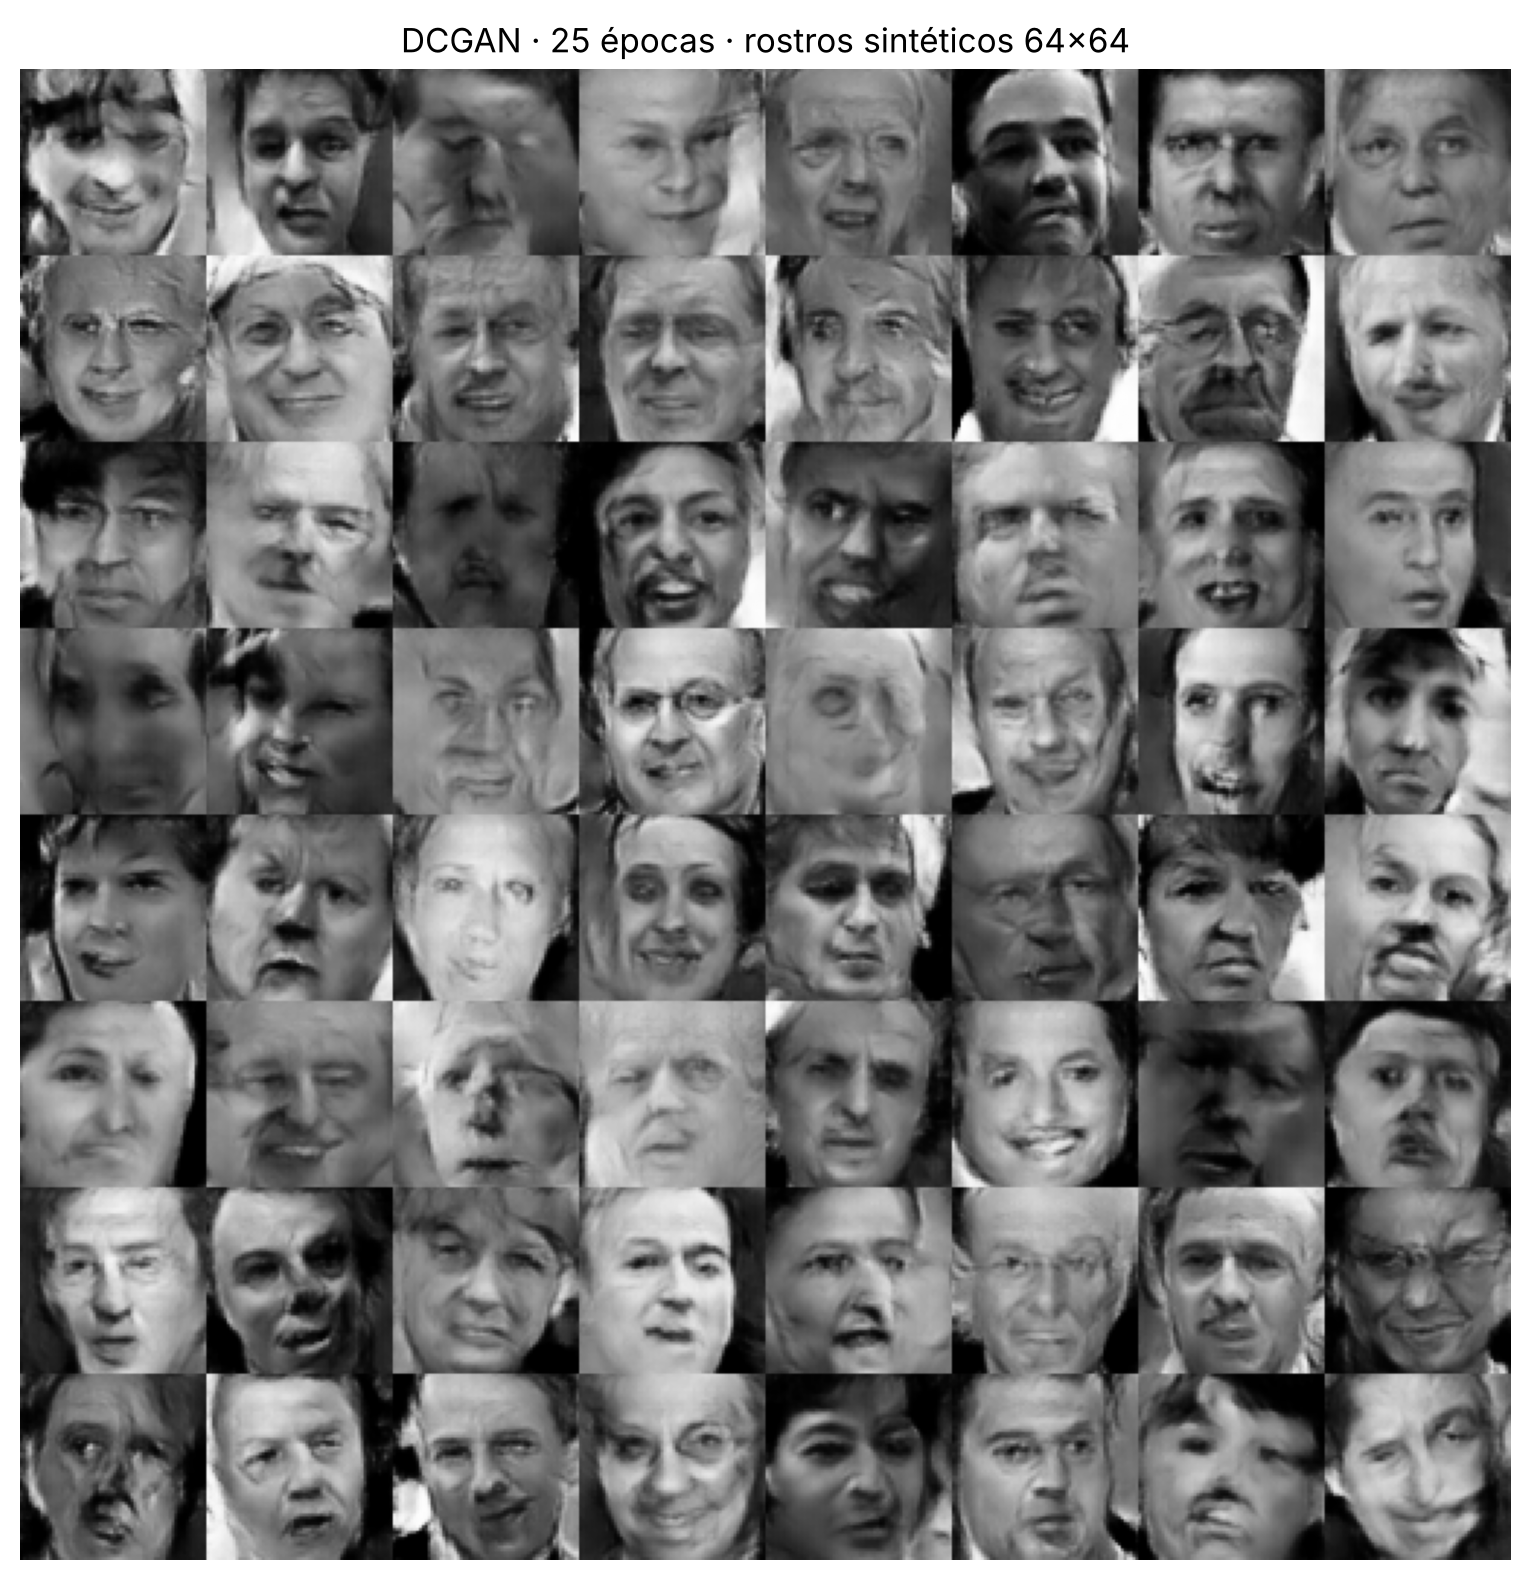

In [8]:
def rejilla(t, filas=8):
    im = a_img(t); n, h, w = im.shape; cols = n // filas
    return im[:filas * cols].reshape(filas, cols, h, w).transpose(0, 2, 1, 3).reshape(filas * h, cols * w)

G.eval()
with torch.no_grad():
    finales = G(ruido_fijo).cpu()
plt.figure(figsize=(8, 8)); plt.imshow(rejilla(finales), cmap='gray', vmin=0, vmax=255); plt.axis('off')
plt.title(f'DCGAN · {EPOCAS} épocas · rostros sintéticos 64×64')
plt.tight_layout(); plt.savefig('figuras/04-rostros-generados-final.png', dpi=150); plt.show()

## 7. Comparación con una GAN básica (capas densas)

Para entender qué aportan las convoluciones, entreno con los mismos datos una **GAN "vainilla"** como la de Goodfellow et al. (2014): generador y discriminador hechos solo con capas densas (*fully connected*). La imagen de 64×64 se trata como un vector de 4 096 valores, así que la red no sabe que los píxeles vecinos están relacionados. La entreno durante 8 épocas (en CPU tardó alrededor de un minuto, porque las capas densas son mucho más baratas que las convoluciones) y la comparo con la DCGAN en las épocas 10 y 25.

Parámetros G-MLP: 4 884 224 | D-MLP: 2 229 249


GAN-MLP época 1 | loss_D 0.931 | loss_G 2.671


GAN-MLP época 2 | loss_D 0.905 | loss_G 3.978


GAN-MLP época 3 | loss_D 1.000 | loss_G 3.599


GAN-MLP época 4 | loss_D 1.083 | loss_G 2.654


GAN-MLP época 5 | loss_D 1.084 | loss_G 2.453


GAN-MLP época 6 | loss_D 1.133 | loss_G 2.175


GAN-MLP época 7 | loss_D 1.124 | loss_G 2.391


GAN-MLP época 8 | loss_D 1.181 | loss_G 2.031
Tiempo GAN-MLP: 1.1 min


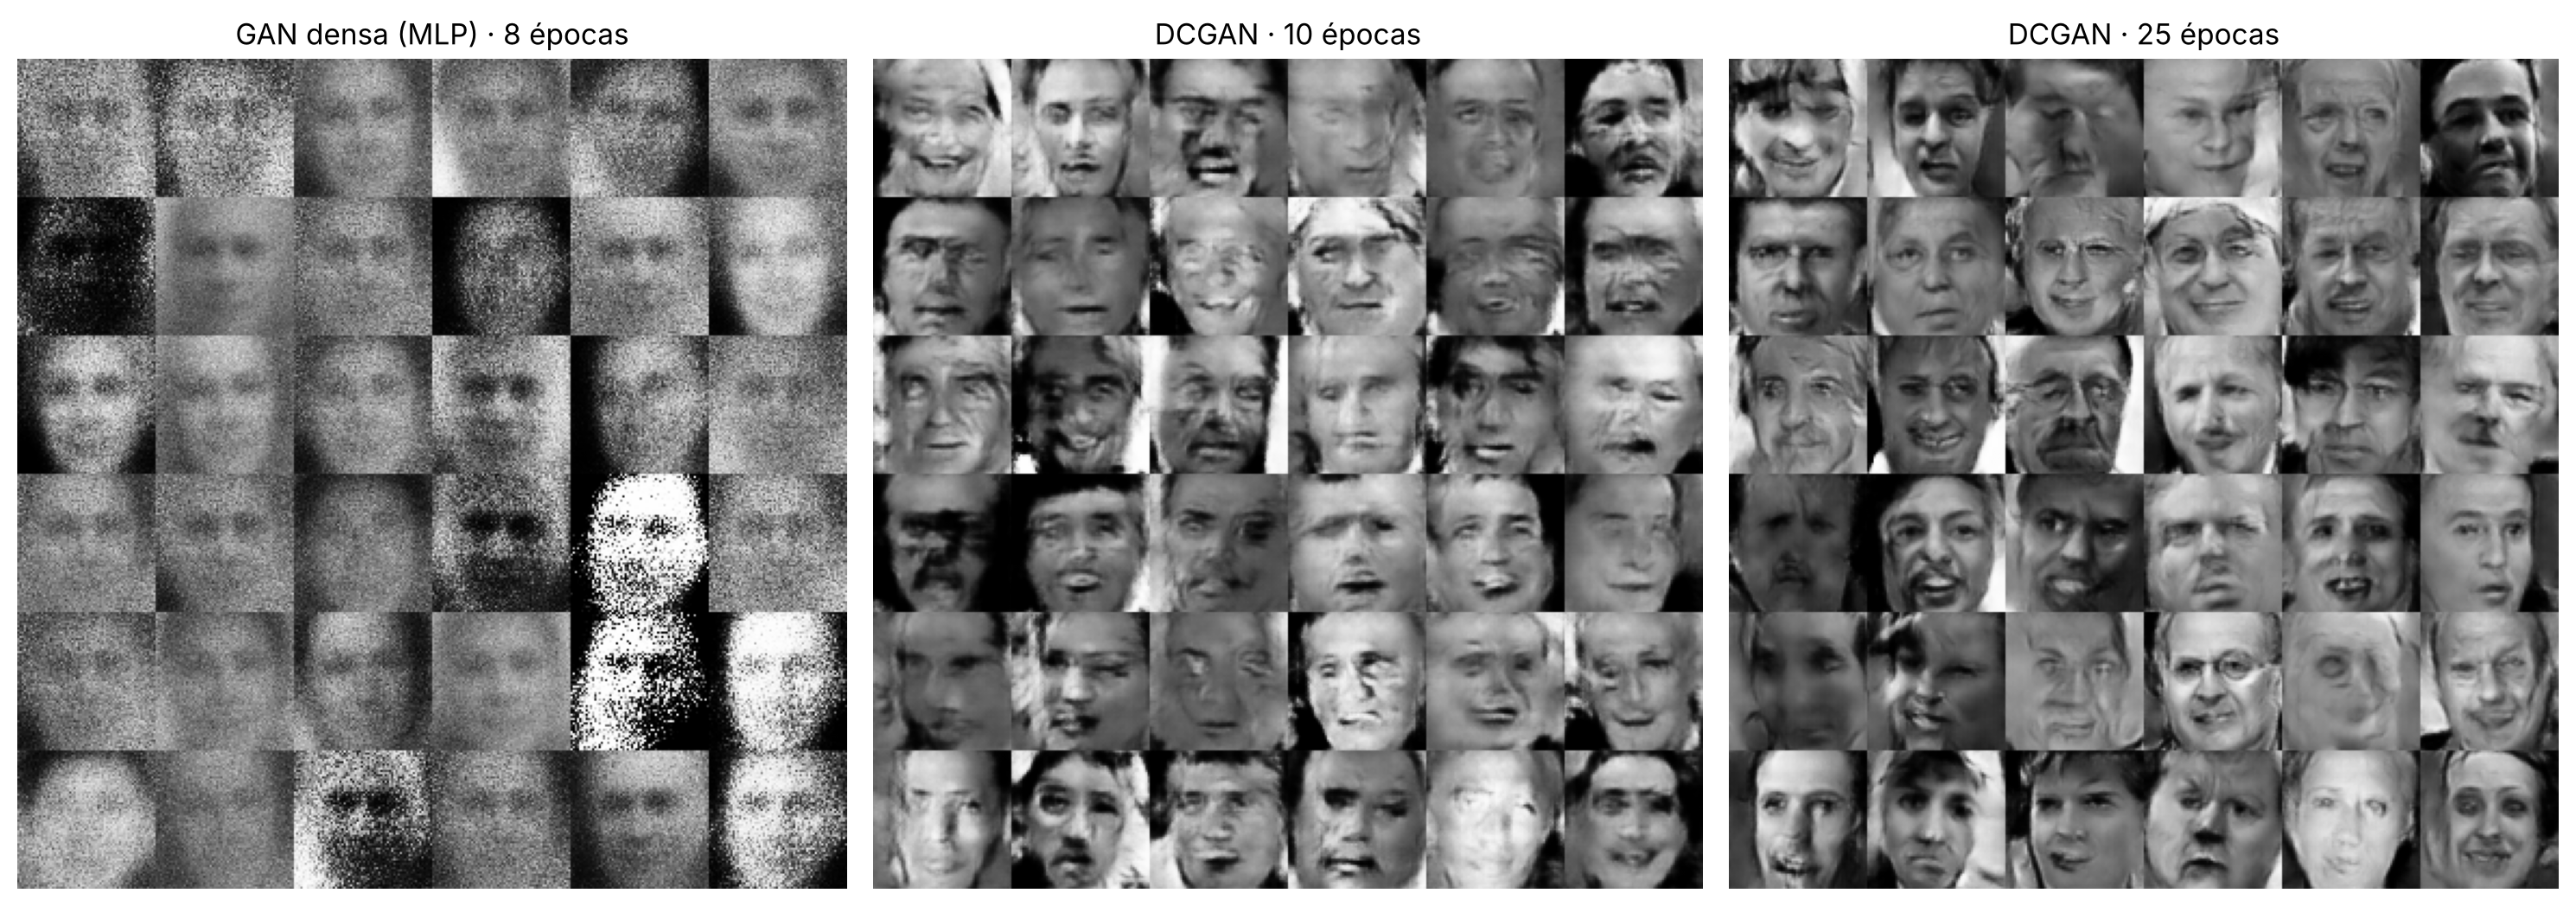

In [9]:
class GeneradorMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.red = nn.Sequential(nn.Linear(NZ, 256), nn.LeakyReLU(0.2, True), nn.Linear(256, 512), nn.BatchNorm1d(512), nn.LeakyReLU(0.2, True),
                                 nn.Linear(512, 1024), nn.BatchNorm1d(1024), nn.LeakyReLU(0.2, True), nn.Linear(1024, TAM * TAM), nn.Tanh())
    def forward(self, z): return self.red(z.view(z.size(0), -1)).view(-1, 1, TAM, TAM)

class DiscriminadorMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.red = nn.Sequential(nn.Flatten(), nn.Linear(TAM * TAM, 512), nn.LeakyReLU(0.2, True),
                                 nn.Linear(512, 256), nn.LeakyReLU(0.2, True), nn.Linear(256, 1))
    def forward(self, x): return self.red(x).view(-1)

torch.manual_seed(SEMILLA)
Gm, Dm = GeneradorMLP().to(dispositivo), DiscriminadorMLP().to(dispositivo)
print('Parámetros G-MLP: {:,} | D-MLP: {:,}'.format(contar(Gm), contar(Dm)).replace(',', ' '))
oGm = torch.optim.Adam(Gm.parameters(), lr=LR, betas=(0.5, 0.999)); oDm = torch.optim.Adam(Dm.parameters(), lr=LR, betas=(0.5, 0.999))
hist_mlp = {'loss_D': [], 'loss_G': []}; t0 = time.time()
for epoca in range(1, 9):
    for (reales,) in cargador:
        reales = reales.to(dispositivo); b = reales.size(0)
        falsas = Gm(torch.randn(b, NZ, 1, 1, device=dispositivo))
        oDm.zero_grad()
        lD = criterio(Dm(reales), torch.full((b,), ETIQ_REAL, device=dispositivo)) + criterio(Dm(falsas.detach()), torch.zeros(b, device=dispositivo))
        lD.backward(); oDm.step()
        oGm.zero_grad(); lG = criterio(Dm(falsas), torch.ones(b, device=dispositivo)); lG.backward(); oGm.step()
        hist_mlp['loss_D'].append(lD.item()); hist_mlp['loss_G'].append(lG.item())
    print(f"GAN-MLP época {epoca} | loss_D {np.mean(hist_mlp['loss_D'][-len(cargador):]):.3f} | loss_G {np.mean(hist_mlp['loss_G'][-len(cargador):]):.3f}")
t_mlp = time.time() - t0
print(f'Tiempo GAN-MLP: {t_mlp/60:.1f} min')

Gm.eval()
with torch.no_grad():
    muestras_mlp = Gm(ruido_fijo).cpu()
fig, ax = plt.subplots(1, 3, figsize=(15, 5.4))
for a, t, tit in zip(ax, [muestras_mlp[:36], instantaneas[10][:36], finales[:36]],
                     ['GAN densa (MLP) · 8 épocas', 'DCGAN · 10 épocas', f'DCGAN · {EPOCAS} épocas']):
    a.imshow(rejilla(t, 6), cmap='gray', vmin=0, vmax=255); a.set_title(tit); a.axis('off')
plt.tight_layout(); plt.savefig('figuras/05-comparacion-mlp-vs-dcgan.png', dpi=150); plt.show()

## 8. Exploración del espacio latente

Si el generador aprendió una representación continua, al recorrer una línea entre dos puntos $z_1$ y $z_2$ el rostro debe transformarse de forma gradual (sin saltos ni imágenes rotas). Uso **interpolación esférica (slerp)**, recomendada por White (2016) porque los vectores gaussianos de 100 dimensiones se concentran cerca de una esfera y la interpolación lineal pasaría por puntos de norma atípica.

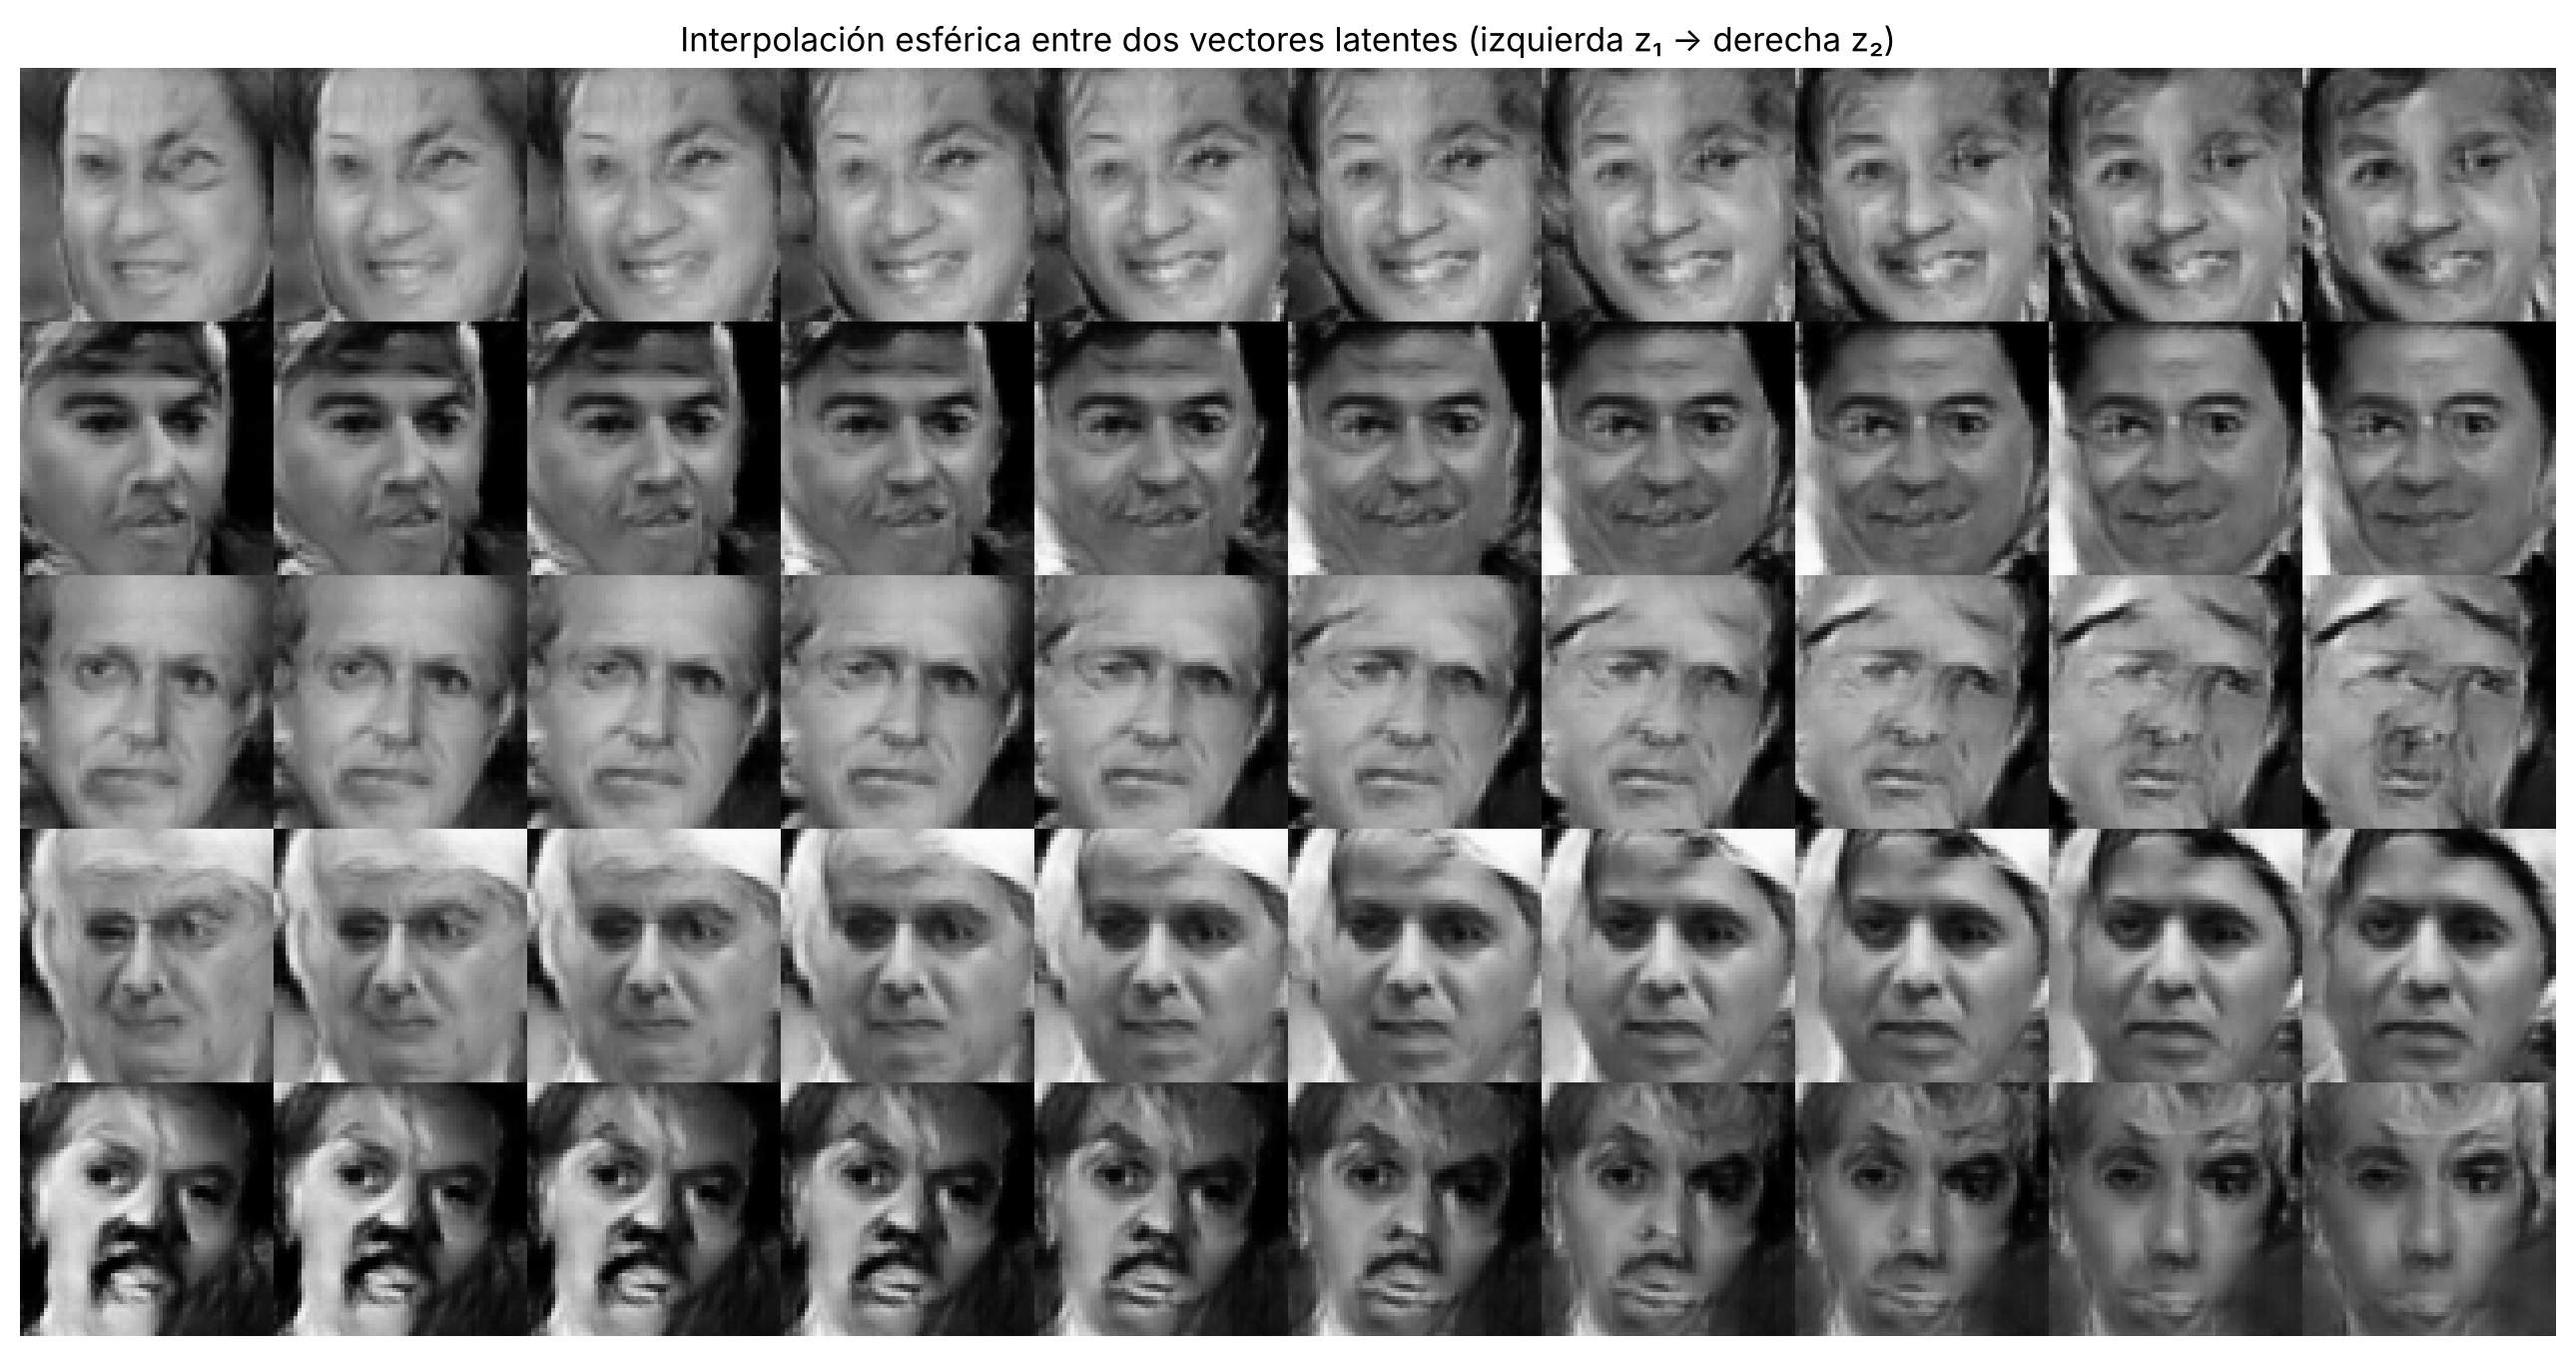

In [10]:
def slerp(a, b, t):
    a_n, b_n = a / a.norm(), b / b.norm()
    omega = torch.acos((a_n * b_n).sum().clamp(-1, 1))
    so = torch.sin(omega)
    return (torch.sin((1 - t) * omega) / so) * a + (torch.sin(t * omega) / so) * b

gen = torch.Generator(device='cpu').manual_seed(7)
pasos = torch.linspace(0, 1, 10)
filas = []
for _ in range(5):
    z1, z2 = torch.randn(NZ, 1, 1, generator=gen), torch.randn(NZ, 1, 1, generator=gen)
    zs = torch.stack([slerp(z1, z2, t) for t in pasos]).to(dispositivo)
    with torch.no_grad():
        filas.append(np.concatenate(list(a_img(G(zs).cpu())), axis=1))
plt.figure(figsize=(13, 6.8)); plt.imshow(np.concatenate(filas, 0), cmap='gray', vmin=0, vmax=255); plt.axis('off')
plt.title('Interpolación esférica entre dos vectores latentes (izquierda z₁ → derecha z₂)')
plt.tight_layout(); plt.savefig('figuras/06-interpolacion-latente.png', dpi=150); plt.show()

También pruebo qué tanto influye cada dirección del espacio latente: tomo un rostro base y sumo $\pm\alpha$ veces una dirección aleatoria $d$ (normalizada). Si los rostros cambian de forma coherente (iluminación, orientación, expresión) el espacio latente está organizado.

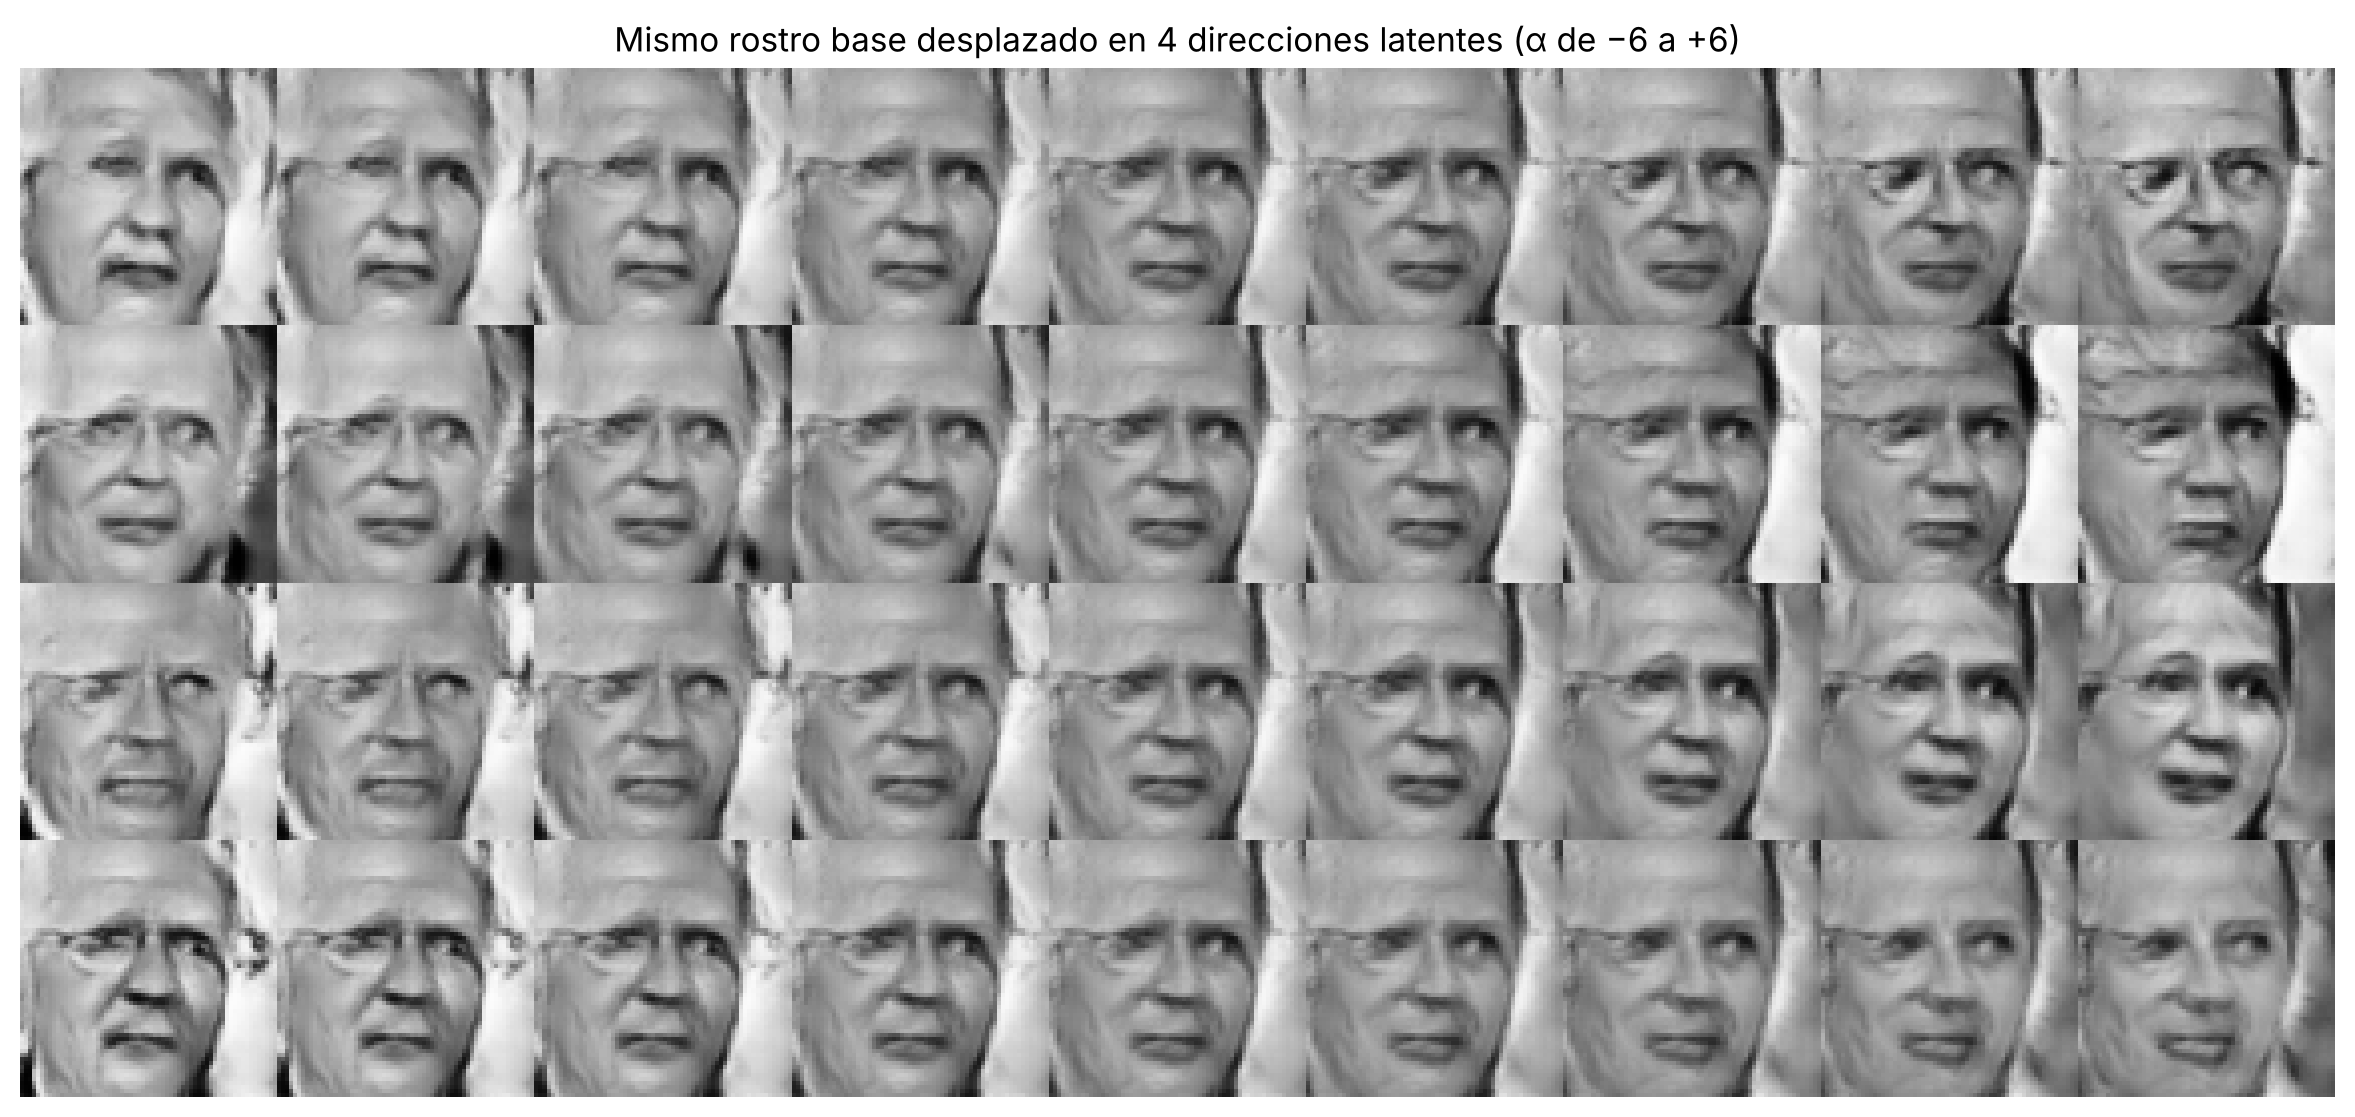

In [11]:
gen = torch.Generator(device='cpu').manual_seed(11)
z_base = torch.randn(NZ, 1, 1, generator=gen)
alfas = torch.linspace(-6, 6, 9)
filas = []
for _ in range(4):
    d = torch.randn(NZ, 1, 1, generator=gen); d = d / d.norm()
    zs = torch.stack([z_base + a * d for a in alfas]).to(dispositivo)
    with torch.no_grad():
        filas.append(np.concatenate(list(a_img(G(zs).cpu())), axis=1))
plt.figure(figsize=(12, 5.6)); plt.imshow(np.concatenate(filas, 0), cmap='gray', vmin=0, vmax=255); plt.axis('off')
plt.title('Mismo rostro base desplazado en 4 direcciones latentes (α de −6 a +6)')
plt.tight_layout(); plt.savefig('figuras/07-direcciones-latentes.png', dpi=150); plt.show()

## 9. Pruebas: ¿la GAN memoriza o genera rostros nuevos?

Una preocupación con las GAN entrenadas con pocos datos es que el generador simplemente copie imágenes del entrenamiento. Para comprobarlo uso el **conjunto de control** (5 % de rostros reales que la red nunca vio):

- **Distancia al vecino más cercano (VMC):** para cada imagen calculo la distancia euclidiana al rostro de entrenamiento más parecido. Si las imágenes generadas estuvieran copiadas, su distancia sería mucho menor que la de los rostros reales de control.
- **Diversidad:** distancia promedio entre pares de imágenes dentro de un mismo grupo. Si es muy baja hay *colapso de modo* (el generador produce casi siempre la misma cara).
- **Estadísticas de píxel:** media y desviación de intensidad, comparadas con las reales.

Grupo                  | VMC media | VMC p5 | Diversidad | Media px | Desv px
Reales de control      |     16.91 |  12.45 |      33.25 |    120.1 |    52.8
DCGAN (25 épocas)      |     18.63 |  14.02 |      34.95 |    117.9 |    55.9
GAN densa (8 épocas)   |     20.67 |  12.67 |      37.40 |    116.0 |    65.4


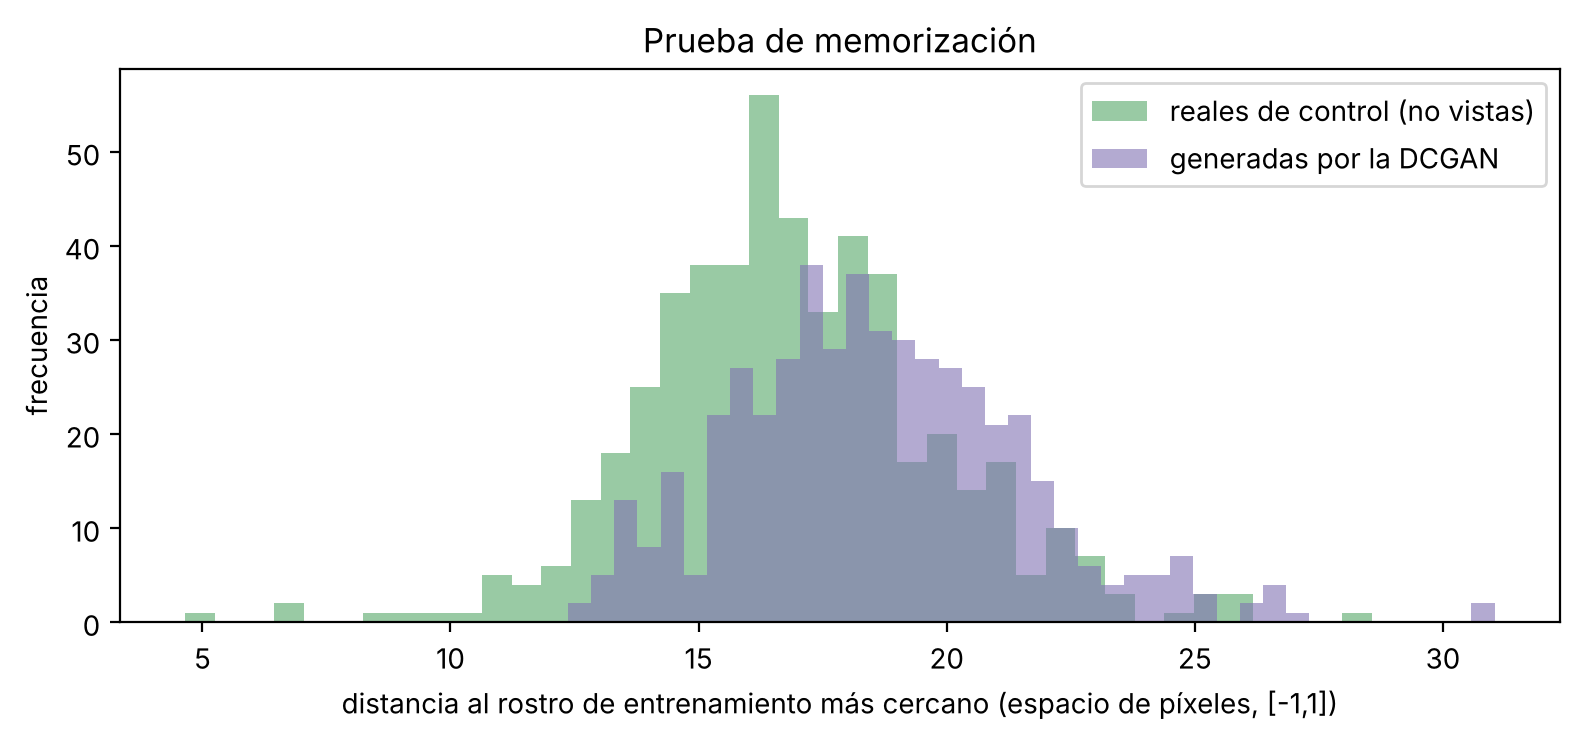

In [12]:
torch.manual_seed(123)
with torch.no_grad():
    gen_eval = torch.cat([G(torch.randn(250, NZ, 1, 1, device=dispositivo)).cpu() for _ in range(2)])     # 500 rostros
    mlp_eval = torch.cat([Gm(torch.randn(250, NZ, 1, 1, device=dispositivo)).cpu() for _ in range(2)])
ctrl_eval = X_control[:500]
E = X_entren.view(len(X_entren), -1)

def dist_vmc(Q):
    Q = Q.view(len(Q), -1); mins = []
    for i in range(0, len(Q), 100):
        mins.append(torch.cdist(Q[i:i + 100], E).min(1).values)
    return torch.cat(mins).numpy()

def diversidad(Q):
    Q = Q.view(len(Q), -1); d = torch.cdist(Q, Q)
    return d[~torch.eye(len(Q), dtype=bool)].mean().item()

filas_tabla = []
for nombre, Q in [('Reales de control', ctrl_eval), (f'DCGAN ({EPOCAS} épocas)', gen_eval), ('GAN densa (8 épocas)', mlp_eval)]:
    v = dist_vmc(Q); px = Q.add(1).mul(127.5)
    filas_tabla.append((nombre, v.mean(), np.percentile(v, 5), diversidad(Q), px.mean().item(), px.std().item()))
    if nombre.startswith('DCGAN'): vmc_gan = v
    if nombre.startswith('Reales'): vmc_ctrl = v

print(f"{'Grupo':22s} | VMC media | VMC p5 | Diversidad | Media px | Desv px")
for f in filas_tabla:
    print(f"{f[0]:22s} | {f[1]:9.2f} | {f[2]:6.2f} | {f[3]:10.2f} | {f[4]:8.1f} | {f[5]:7.1f}")

plt.figure(figsize=(8, 3.8))
plt.hist(vmc_ctrl, bins=40, alpha=.6, label='reales de control (no vistas)', color='#55A868')
plt.hist(vmc_gan, bins=40, alpha=.6, label='generadas por la DCGAN', color='#8172B3')
plt.xlabel('distancia al rostro de entrenamiento más cercano (espacio de píxeles, [-1,1])'); plt.ylabel('frecuencia')
plt.title('Prueba de memorización'); plt.legend()
plt.tight_layout(); plt.savefig('figuras/08-prueba-memorizacion.png', dpi=150); plt.show()

## 10. Análisis y conclusiones

Resultados obtenidos en esta ejecución (CPU, 2 hilos, 50,2 minutos de entrenamiento para la DCGAN):

**Dinámica adversarial.** Las pérdidas no bajan de forma monótona como en un clasificador: suben y bajan porque cada red cambia el problema de la otra. Lo importante es que ninguna de las dos "gane" por completo. Si $D(G(z))$ llegara a 0 el generador dejaría de recibir gradiente útil; si $D(x)$ cayera a 0,5 desde el principio el discriminador no estaría aprendiendo. En este entrenamiento D(x) bajó de 0,82 a 0,69 y D(G(z)) subió de 0,09 a 0,21, mientras la pérdida del generador cayó de 6,20 a 2,66. Desde la época 15 los valores se estabilizan: el discriminador sigue por delante, que es lo típico en una DCGAN, pero no logra rechazar del todo las imágenes falsas y el generador sigue recibiendo gradiente útil.

**Calidad visual.** En la primera época solo aparece una mancha oval con la forma promedio de una cara. Entre las épocas 3 y 5 aparecen ojos, nariz y boca en las posiciones correctas, y al final los rostros tienen variaciones de iluminación, orientación, cabello y expresión. Siguen teniendo defectos típicos de una DCGAN pequeña: asimetrías, ojos de distinto tamaño, bordes borrosos y fondos poco definidos.

**Convoluciones frente a capas densas.** La GAN densa produce imágenes mucho más ruidosas y con menos estructura local, aunque capta el contorno general. La DCGAN aprovecha que los píxeles vecinos están relacionados (sesgo inductivo de la convolución) y comparte pesos, por eso logra mejores resultados con menos parámetros.

**Espacio latente.** Las interpolaciones son suaves: no hay saltos bruscos, lo que indica que el generador aprendió una representación continua y no una tabla de caras memorizadas.

**Memorización.** La distancia media de los rostros generados a su vecino más cercano del entrenamiento fue 18,63, mayor que la de los rostros reales nunca vistos (16,91). Si la red copiara imágenes, esa distancia sería mucho menor. Además la diversidad de las muestras (34,95) es similar a la de los rostros reales (33,25), así que no hay colapso de modo.

**Limitaciones.** Entrené en CPU, en escala de grises y a 64×64. Con GPU, imágenes a color (CelebA) y más épocas los resultados serían más nítidos. Tampoco calculé FID porque requiere descargar la red Inception; las métricas de la sección 9 son una aproximación sencilla.

### Referencias
- Goodfellow, I. et al. (2014). *Generative adversarial nets*. NeurIPS.
- Radford, A., Metz, L. y Chintala, S. (2016). *Unsupervised representation learning with deep convolutional generative adversarial networks*. ICLR.
- Salimans, T. et al. (2016). *Improved techniques for training GANs*. NeurIPS.
- White, T. (2016). *Sampling generative networks*. arXiv:1609.04468.
- Implementing a Generative Adversarial Network (GAN/DCGAN) to Draw Human Faces (lectura del curso).
- Conjunto de datos: muxspace/facial_expressions (GitHub, licencia Apache 2.0).